# K-Means Clustering: Anime Groups

**Question:** Can we group anime by their score, popularity, episodes and release year?

**Aim:** Find groups of anime with similar features, then see what makes each group different.

**Plan:** Check the data, scale the features, test cluster numbers, make clusters and compare them.

## 1. Load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

df = pd.read_csv("../data/cleaned_popular_anime.csv")
print("Dataset rows:", len(df))
df.head()

Dataset rows: 28607


,id,name,genres,type,episodes,status,aired_from,aired_to,duration_per_ep,score,scored_by,rank,rating,studios,producers,image,trailer,synopsis,release_year
0,52991,Frieren: Beyond Journey's End,"Adventure, Drama, Fantasy",TV,28.0,Finished Airing,2023-09-29 00:00:00+00:00,2024-03-22 00:00:00+00:00,24 min per ep,9.30,676737.0,1.0,PG-13 - Teens 13 or older,Madhouse,"Aniplex, Dentsu, Shogakukan-Shueisha Productio...",https://cdn.myanimelist.net/images/anime/1015/...,https://www.youtube.com/watch?v=ZEkwCGJ3o7M,During their decade-long quest to defeat the D...,2023.0
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy",TV,64.0,Finished Airing,2009-04-05 00:00:00+00:00,2010-07-04 00:00:00+00:00,24 min per ep,9.10,2223666.0,2.0,R - 17+ (violence & profanity),Bones,"Aniplex, Square Enix, Mainichi Broadcasting Sy...",https://cdn.myanimelist.net/images/anime/1208/...,https://www.youtube.com/watch?v=1ac3_YdSSy0,After a horrific alchemy experiment goes wrong...,2009.0
2,9253,Steins;Gate,"Drama, Sci-Fi, Suspense",TV,24.0,Finished Airing,2011-04-06 00:00:00+00:00,2011-09-14 00:00:00+00:00,24 min per ep,9.07,1467570.0,3.0,PG-13 - Teens 13 or older,White Fox,"Frontier Works, Media Factory, Kadokawa Shoten...",https://cdn.myanimelist.net/images/anime/1935/...,https://www.youtube.com/watch?v=27OZc-ku6is,Eccentric scientist Rintarou Okabe has a never...,2011.0
3,38524,Attack on Titan Season 3 Part 2,"Action, Drama, Suspense",TV,10.0,Finished Airing,2019-04-29 00:00:00+00:00,2019-07-01 00:00:00+00:00,23 min per ep,9.05,1700946.0,4.0,R - 17+ (violence & profanity),Wit Studio,"Production I.G, Dentsu, Mainichi Broadcasting ...",https://cdn.myanimelist.net/images/anime/1517/...,https://www.youtube.com/watch?v=hKHepjfj5Tw,Seeking to restore humanity's diminishing hope...,2019.0
4,28977,Gintama Season 4,"Action, Comedy, Sci-Fi",TV,51.0,Finished Airing,2015-04-08 00:00:00+00:00,2016-03-30 00:00:00+00:00,24 min per ep,9.05,264260.0,5.0,PG-13 - Teens 13 or older,Bandai Namco Pictures,"TV Tokyo, Aniplex, Dentsu",https://cdn.myanimelist.net/images/anime/3/720...,NaN,"Gintoki, Shinpachi, and Kagura return as the f...",2015.0


## 2. Choose the features
Use score, number of ratings, episodes and release year. These are numbers so they work well for K-Means.

In [2]:
features = ["score", "scored_by", "episodes", "release_year"]
data = df.dropna(subset=features).copy()
data = data[(data["scored_by"] > 0) & (data["episodes"] > 0)]
data = data[data["release_year"] <= 2026]
print("Anime used:", len(data))
display(data[features].describe().round(1))

Anime used: 18405


,score,scored_by,episodes,release_year
count,18405.0,18405.0,18405.0,18405.0
mean,6.4,30095.7,11.0,2008.4
std,0.9,121450.3,47.7,14.6
min,1.9,101.0,1.0,1917.0
25%,5.8,341.0,1.0,2003.0
50%,6.4,1572.0,2.0,2013.0
75%,7.0,10285.0,12.0,2019.0
max,9.3,2943048.0,3057.0,2025.0


The number of ratings and episodes have some very large values. Use log values so these do not dominate the clusters.

In [3]:
data["log_ratings"] = np.log1p(data["scored_by"])
data["log_episodes"] = np.log1p(data["episodes"])
cluster_features = ["score", "log_ratings", "log_episodes", "release_year"]
display(data[cluster_features].describe().round(2))

,score,log_ratings,log_episodes,release_year
count,18405.00,18405.00,18405.00,18405.00
mean,6.39,7.72,1.61,2008.44
std,0.89,2.20,1.13,14.57
min,1.89,4.62,0.69,1917.00
25%,5.77,5.83,0.69,2003.00
50%,6.37,7.36,1.10,2013.00
75%,7.03,9.24,2.56,2019.00
max,9.30,14.89,8.03,2025.00


## 3. Look at the features

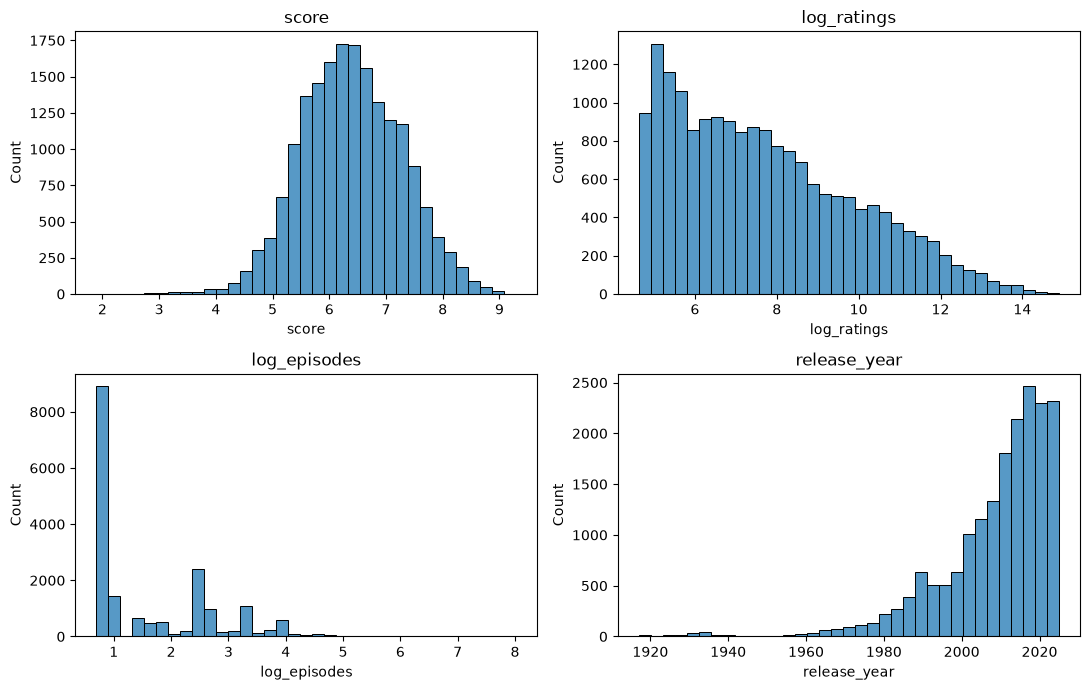

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, column in zip(axes.flat, cluster_features):
    sns.histplot(data[column], bins=35, ax=ax)
    ax.set_title(column)
plt.tight_layout()
plt.show()

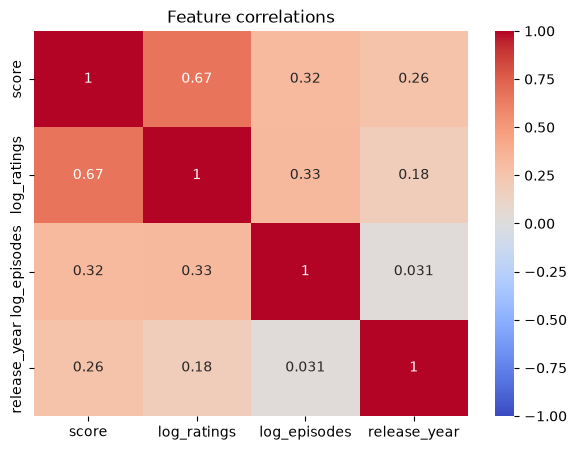

In [5]:
plt.figure(figsize=(7, 5))
sns.heatmap(data[cluster_features].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Feature correlations")
plt.show()

## 4. Scale the features
K-Means uses distance. Scaling stops release year or rating count from having more influence just because of its number range.

In [6]:
scaler = StandardScaler()
X = scaler.fit_transform(data[cluster_features])
print("Scaled data shape:", X.shape)

Scaled data shape: (18405, 4)


## 5. Find a cluster number
Test 2 to 7 clusters. The elbow graph shows how much the within-cluster distance drops. Silhouette score checks how separate the groups are.

In [7]:
cluster_numbers = range(2, 8)
inertias = []
silhouettes = []
for k in cluster_numbers:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X, labels, sample_size=min(2000, len(X)), random_state=42))
results = pd.DataFrame({"clusters": list(cluster_numbers), "inertia": inertias, "silhouette": silhouettes})
display(results.round(3))

,clusters,inertia,silhouette
0,2,48518.291,0.325
1,3,39045.331,0.304
2,4,31859.660,0.302
3,5,26725.697,0.301
4,6,23765.133,0.310
5,7,21316.949,0.299


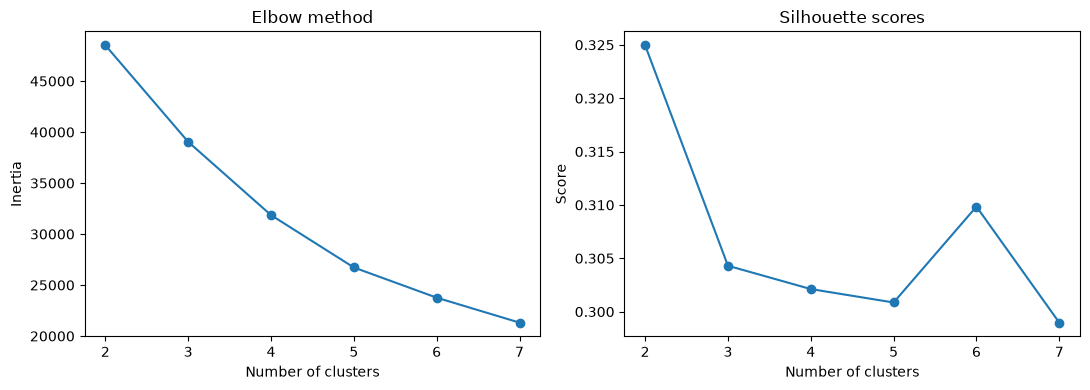

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(results["clusters"], results["inertia"], marker="o")
axes[0].set(title="Elbow method", xlabel="Number of clusters", ylabel="Inertia")
axes[1].plot(results["clusters"], results["silhouette"], marker="o")
axes[1].set(title="Silhouette scores", xlabel="Number of clusters", ylabel="Score")
plt.tight_layout()
plt.show()

## 6. Make the clusters
Use the number with the best silhouette score from the tested values. It is a starting point, not a perfect answer.

In [9]:
chosen_k = int(results.loc[results["silhouette"].idxmax(), "clusters"])
print("Chosen clusters:", chosen_k)
kmeans = KMeans(n_clusters=chosen_k, random_state=42, n_init=10)
data["cluster"] = kmeans.fit_predict(X)
print(data["cluster"].value_counts().sort_index())

Chosen clusters: 2
cluster
0     8091
1    10314
Name: count, dtype: int64


## 8. Visualise the clusters
PCA reduces the four features to two dimensions so we can draw them. This is only a view of the clusters, not all the information used by K-Means.